# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Rafa Rizki Aira Swala | 5054251017 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [26]:
# Import library yang dibutuhkan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setting tampilan
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

In [27]:
# Load dataset
# Sesuaikan nama file dengan file dataset yang digunakan

df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [28]:
# Tampilkan beberapa baris pertama dataset

df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [29]:
# Tampilkan informasi dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [30]:
# Periksa missing value

df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [31]:
# Tampilkan statistik deskriptif fitur numerik

df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [32]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal

cat_cols = ['sex', 'smoker', 'region']

for col in cat_cols:
    print(f"Kolom: {col}")
    print(df[col].value_counts())
    print()

Kolom: sex
sex
male      676
female    662
Name: count, dtype: int64

Kolom: smoker
smoker
no     1064
yes     274
Name: count, dtype: int64

Kolom: region
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64



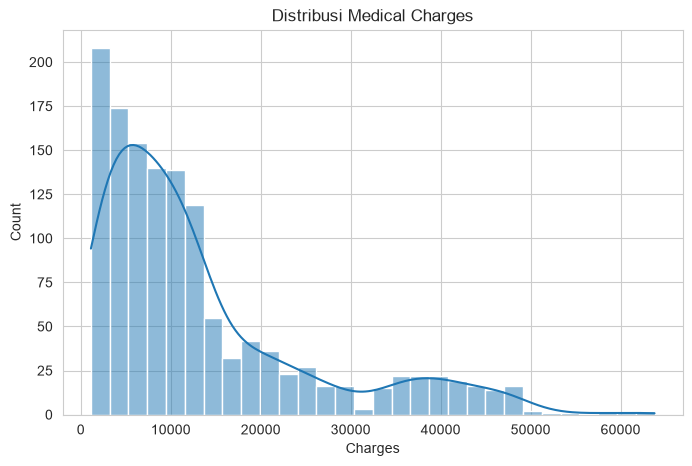

In [33]:
# Distribusi target (charges)

plt.figure(figsize=(8, 5))
sns.histplot(df['charges'], kde=True, bins=30)
plt.title('Distribusi Medical Charges')
plt.xlabel('Charges')
plt.show()

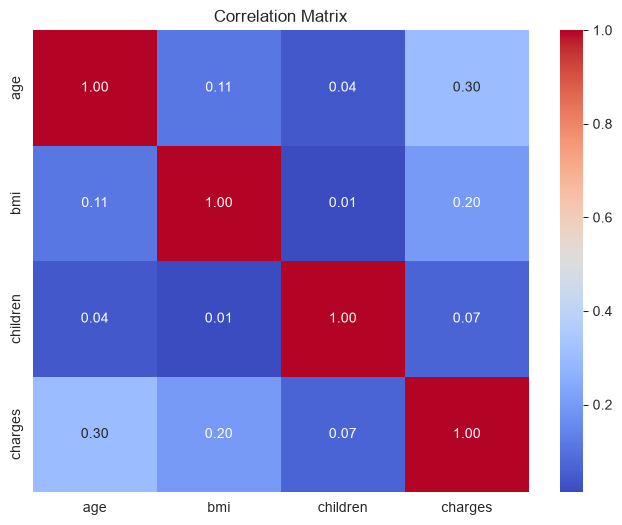

In [34]:
# Heatmap korelasi fitur numerik

plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=['int64', 'float64']).corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [35]:
# Rata-rata charges berdasarkan fitur kategorikal

for col in ['sex', 'smoker', 'region']:
    print(f"Rata-rata charges berdasarkan {col}:")
    print(df.groupby(col)['charges'].mean().sort_values(ascending=False))
    print()

Rata-rata charges berdasarkan sex:
sex
male      13956.751178
female    12569.578844
Name: charges, dtype: float64

Rata-rata charges berdasarkan smoker:
smoker
yes    32050.231832
no      8434.268298
Name: charges, dtype: float64

Rata-rata charges berdasarkan region:
region
southeast    14735.411438
northeast    13406.384516
northwest    12417.575374
southwest    12346.937377
Name: charges, dtype: float64



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [36]:
# Pisahkan fitur (X) dan target (y)

X = df.drop(columns='charges')
y = df['charges']

print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (1338, 6)
Shape y: (1338,)


In [37]:
# Identifikasi kolom numerik dan kategorikal

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print('Kolom numerik :', num_cols)
print('Kolom kategorikal:', cat_cols)

Kolom numerik : ['age', 'bmi', 'children']
Kolom kategorikal: ['sex', 'smoker', 'region']


C:\Users\airal\AppData\Local\Temp\ipykernel_30028\1327797520.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns.tolist()


In [38]:
# Bagi data menjadi train set dan test set

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (1070, 6)
X_test : (268, 6)
y_train: (1070,)
y_test : (268,)


In [39]:
# Buat preprocessing untuk fitur numerik dan kategorikal

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Fitur numerik: scaling
num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Fitur kategorikal: one-hot encoding
cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Gabungkan
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [40]:
# Cek hasil transformasi preprocessing

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print('Shape X_train setelah preprocessing:', X_train_prep.shape)
print('Shape X_test setelah preprocessing :', X_test_prep.shape)

Shape X_train setelah preprocessing: (1070, 11)
Shape X_test setelah preprocessing : (268, 11)


# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [41]:
# Inisialisasi dan latih Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linreg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [42]:
# Lakukan prediksi pada test set

y_pred_linreg = linreg.predict(X_test)
y_pred_linreg[:5]

array([ 8969.55027444,  7068.74744287, 36858.41091155,  9454.67850053,
       26973.17345656])

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [43]:
# Buat fitur polynomial dan latih model

from sklearn.preprocessing import PolynomialFeatures

# Polynomial hanya untuk fitur numerik agar tidak meledak dimensi
num_transformer_poly = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False))
])

preprocessor_poly = ColumnTransformer(transformers=[
    ('num', num_transformer_poly, num_cols),
    ('cat', cat_transformer, cat_cols)
])

polyreg = Pipeline(steps=[
    ('preprocessor', preprocessor_poly),
    ('model', LinearRegression())
])

polyreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [44]:
# Lakukan prediksi pada test set

y_pred_poly = polyreg.predict(X_test)
y_pred_poly[:5]

array([ 8544.0042068 ,  6192.01730158, 38632.19645463,  8670.3204163 ,
       27802.7003195 ])

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [45]:
# Inisialisasi dan latih Ridge Regression

from sklearn.linear_model import Ridge

ridge = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0, random_state=42))
])

ridge.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [46]:
# Lakukan prediksi pada test set

y_pred_ridge = ridge.predict(X_test)
y_pred_ridge[:5]

array([ 8979.95466915,  7079.65062176, 36792.69449533,  9468.40383721,
       26924.2040913 ])

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [47]:
# Inisialisasi dan latih Lasso Regression

from sklearn.linear_model import Lasso

lasso = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=1.0, random_state=42, max_iter=10000))
])

lasso.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [48]:
# Lakukan prediksi pada test set

y_pred_lasso = lasso.predict(X_test)
y_pred_lasso[:5]

array([ 8964.99606188,  7064.32364784, 36846.39348515,  9453.48079986,
       26967.0401981 ])

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [49]:
# Inisialisasi dan latih Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor

dtree = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

dtree.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [50]:
# Lakukan prediksi pada test set

y_pred_dtree = dtree.predict(X_test)
y_pred_dtree[:5]

array([ 9500.57305,  5266.3656 , 28950.4692 ,  9500.57305, 33732.6867 ])

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [51]:
# Inisialisasi dan latih Support Vector Regression

from sklearn.svm import SVR

svr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVR(kernel='rbf', C=1000, gamma='scale', epsilon=0.1))
])

svr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [52]:
# Lakukan prediksi pada test set

y_pred_svr = svr.predict(X_test)
y_pred_svr[:5]

array([ 9116.82922684,  5309.75380022, 24629.44320473,  9419.45449331,
       19370.06859148])

# 4. Evaluasi Model

In [53]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model
# Sajikan hasil dalam satu tabel perbandingan

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Kumpulkan prediksi tiap model
preds = {
    'Linear Regression'    : y_pred_linreg,
    'Polynomial Regression': y_pred_poly,
    'Ridge Regression'     : y_pred_ridge,
    'Lasso Regression'     : y_pred_lasso,
    'Decision Tree'        : y_pred_dtree,
    'SVR'                  : y_pred_svr
}

# Hitung metrik
results = []
for name, y_pred in preds.items():
    mae  = mean_absolute_error(y_test, y_pred)
    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE'  : mae,
        'MSE'  : mse,
        'RMSE' : rmse,
        'R²'   : r2
    })

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,4181.194474,3.359692e+07,5796.284659,0.783593
1,Lasso Regression,4182.081076,3.360584e+07,5797.054261,0.783536
2,Ridge Regression,4186.913072,3.362027e+07,5798.298795,0.783443
3,Polynomial Regression,4254.274827,3.412055e+07,5841.280186,0.780220
4,Decision Tree,3227.664954,4.446327e+07,6668.078316,0.713600
5,SVR,3014.462573,4.791658e+07,6922.180492,0.691356


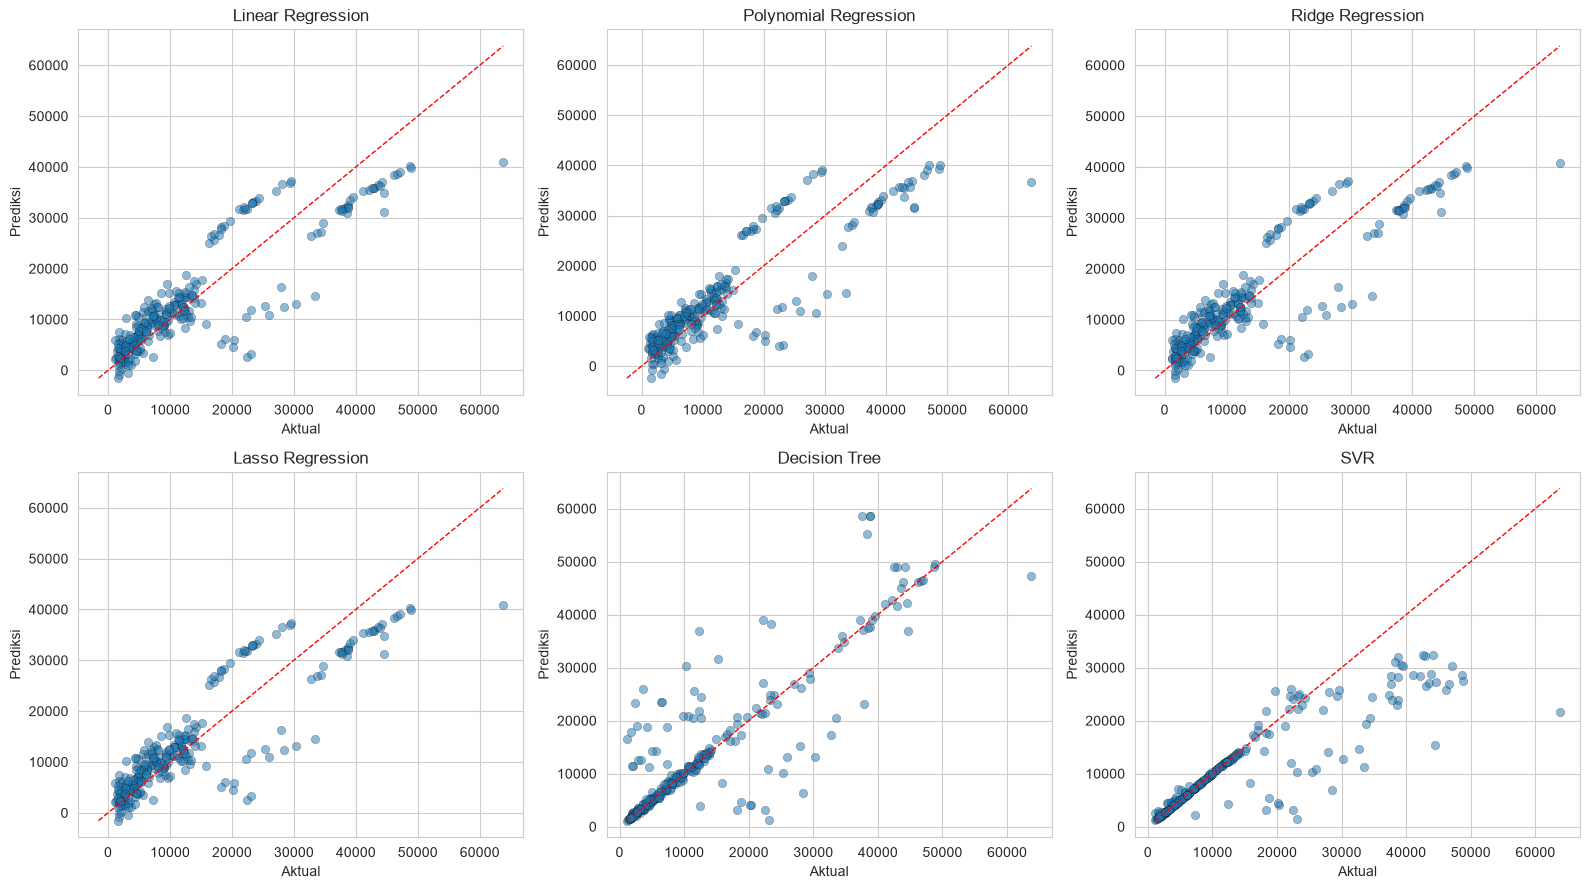

In [ ]:
# Visualisasi perbandingan nilai aktual dan prediksi

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, preds.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, edgecolor='k', linewidth=0.3)
    # Garis ideal (y = x)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('Aktual')
    ax.set_ylabel('Prediksi')

plt.tight_layout()
plt.show()

In [56]:
# Cek fitur yang di-nol-kan Lasso
feature_names = preprocessor.get_feature_names_out()
lasso_coefs = lasso.named_steps['model'].coef_
pd.DataFrame({'feature': feature_names, 'coef': lasso_coefs}).sort_values('coef')

,feature,coef
5,cat__smoker_no,-2.364432e+04
10,cat__region_southwest,-1.523968e+02
4,cat__sex_male,-7.152682e-13
9,cat__region_southeast,-0.000000e+00
6,cat__smoker_yes,2.375914e-10
3,cat__sex_female,1.396812e+01
8,cat__region_northwest,2.781015e+02
2,num__children,5.160386e+02
7,cat__region_northeast,6.491044e+02
1,num__bmi,2.034343e+03


# 5. Analisis

## Perbandingan Performa Model

Berdasarkan tabel evaluasi, keenam model bisa dikelompokkan menjadi dua kelompok besar:

**Kelompok model linear (Linear, Ridge, Lasso, Polynomial):**
- Linear Regression menghasilkan performa terbaik dengan **RMSE 5796.28** dan **R² 0.7836**.
- Lasso dan Ridge berada sangat dekat di bawahnya (selisih RMSE hanya ~1–2 poin). Ini wajar karena Ridge dan Lasso adalah bentuk regularisasi dari regresi linear, sehingga ketika alpha kecil (1.0), hasilnya nyaris identik dengan OLS.
- Polynomial Regression (degree=2) justru sedikit lebih buruk (RMSE 5841.28, R² 0.7802). Artinya hubungan antara fitur dan `charges` tidak banyak yang bersifat non-linear murni pada level interaksi kuadratik, sehingga penambahan fitur polynomial hanya menambah kompleksitas tanpa memberi informasi baru.

**Kelompok model non-linear (Decision Tree, SVR):**
- Decision Tree punya **MAE terkecil (3227.66)** tetapi **RMSE-nya jauh lebih besar (6668.08)** dan **R² paling rendah kedua (0.7136)**.
- SVR punya **MAE terkecil kedua (3014.46)** tetapi **RMSE tertinggi (6922.18)** dan **R² terendah (0.6914)**.

## Kenapa MAE kecil tapi RMSE besar?

Ini poin penting. MAE mengukur error rata-rata, sedangkan RMSE memberi penalti besar pada error yang sangat besar (karena dikuadratkan).

- **Decision Tree**: melihat scatter plot-nya, titik-titik prediksi membentuk pola "tangga" (step). Model ini sangat akurat untuk data yang mirip dengan data training, tetapi begitu menemui sampel dengan `charges` tinggi yang belum pernah dilihat, prediksinya meleset jauh. Error besar inilah yang membuat RMSE meledak meskipun MAE-nya kecil.
- **SVR**: pola titiknya sangat rapat di daerah `charges` rendah, tapi menyebar jauh di `charges` tinggi. Model ini cenderung "underestimate" untuk nilai ekstrem, sehingga lagi-lagi RMSE-nya besar.

Sebaliknya, **Linear Regression** punya MAE lebih besar (4181) tapi RMSE paling kecil. Artinya errornya lebih merata dan tidak ada outlier error yang ekstrem — inilah yang membuat model linear lebih stabil dan `R²`-nya tertinggi.

## Pengaruh Preprocessing

- **StandardScaler** pada fitur numerik sangat penting untuk **Ridge, Lasso, dan SVR**. Ridge dan Lasso memberi penalti yang besarnya bergantung pada skala koefisien, sehingga tanpa scaling penalti akan tidak adil antar fitur. SVR menghitung jarak antar titik, jadi skala fitur langsung mempengaruhi margin.
- Untuk **Linear Regression dan Polynomial Regression**, scaling tidak mengubah performa secara signifikan karena OLS tidak terpengaruh skala, tetapi tidak ada ruginya karena pipeline tetap konsisten.
- **OneHotEncoder** pada fitur kategorikal (`sex`, `smoker`, `region`) mencegah model menganggap kategori punya urutan. Ini penting karena `region` bukan variabel ordinal.

## Pengaruh Parameter

- **Alpha Ridge/Lasso = 1.0**: Nilai ini relatif kecil, sehingga regularisasinya lemah dan hasilnya mendekati Linear Regression. Kalau alpha diperbesar, model bisa jadi lebih bias (underfit), tapi kalau alpha diperkecil malah sama dengan OLS. Hasil saat ini menunjukkan alpha 1.0 sudah cukup seimbang.
- **Polynomial degree = 2**: Cukup untuk menangkap interaksi sederhana, tapi tidak membantu karena datanya memang lebih cocok dimodelkan linear setelah fitur kategorikal (terutama `smoker`) di-encode.
- **SVR C=1000, kernel RBF**: C besar membuat model berusaha keras menyesuaikan data training, tapi dengan hanya fitur dasar (tanpa scaling target), SVR kesulitan menangkap nilai `charges` yang besar. Ini terlihat dari prediksi yang "mentok" di sekitar 20000–30000.
- **Decision Tree default**: Tanpa `max_depth` atau `min_samples_leaf`, pohon tumbuh sangat dalam dan overfit. Ini yang menyebabkan error besar pada data test.

## Insight dari Koefisien Lasso

Lasso memberi petunjuk fitur mana yang paling berpengaruh:
- `num__age` (+3614) dan `num__bmi` (+2034) adalah pendorong utama kenaikan `charges`.
- `cat__smoker_no` (-23644) sangat besar negatif, artinya **bukan perokok** menurunkan biaya medis secara drastis dibanding perokok. Ini konsisten dengan domain knowledge bahwa merokok adalah faktor risiko utama.
- `cat__sex_male` dan `cat__smoker_yes` koefisiennya ~0, artinya untuk data ini kedua fitur tersebut tidak memberi kontribusi tambahan setelah fitur lain diperhitungkan (kemungkinan karena multikolinearitas dengan `smoker_no`).
- Fitur `region` kontribusinya kecil (puluhan sampai ratusan), jauh di bawah `age`, `bmi`, dan `smoker`.

# 6. Kesimpulan dan Saran

## Kesimpulan

1. **Linear Regression adalah model terbaik** pada eksperimen ini dengan RMSE 5796.28 dan R² 0.7836. Model ini menjelaskan sekitar 78% variansi `charges` pada data test dan errornya paling merata (tidak ada outlier error yang ekstrem).

2. **Ridge dan Lasso nyaris identik dengan Linear Regression** (selisih RMSE < 2 poin). Ini karena alpha yang dipakai (1.0) masih kecil, sehingga regularisasi belum memberi efek berarti. Keduanya tetap berguna sebagai bentuk kontrol overfitting kalau nanti dituning lebih lanjut.

3. **Polynomial Regression (degree=2) tidak meningkatkan performa**, bahkan sedikit lebih buruk. Artinya hubungan antara fitur dan `charges` tidak banyak yang bersifat kuadratik murni; menambah fitur polynomial hanya menambah kompleksitas.

4. **Decision Tree dan SVR punya MAE kecil tapi RMSE besar**. Keduanya akurat untuk sampel "biasa" tetapi buruk untuk `charges` tinggi (overfit pada Decision Tree, underfit pada ekstrem untuk SVR). Ini menunjukkan bahwa MAE saja tidak cukup untuk menilai model regresi — perlu dilihat bersama RMSE dan R².

5. **Fitur paling berpengaruh adalah `smoker`, `age`, dan `bmi`**. Dari koefisien Lasso terlihat `smoker_no` menurunkan `charges` sekitar 23.644, sedangkan `age` dan `bmi` menaikkannya masing-masing ~3.614 dan ~2.034 per satuan. Fitur `region` dan `sex` kontribusinya sangat kecil.

6. **Preprocessing berperan penting**, terutama `StandardScaler` untuk Ridge, Lasso, dan SVR, serta `OneHotEncoder` untuk fitur kategorikal. Tanpa keduanya, performa model-model tersebut bisa turun atau tidak adil antar fitur.

## Saran

**Perbaikan model linear:**
- Lakukan **hyperparameter tuning** untuk Ridge dan Lasso menggunakan `GridSearchCV` dengan rentang alpha yang lebih luas (misal 0.001–100). Mungkin saja alpha optimal bisa sedikit mengalahkan OLS.
- Coba **Polynomial degree=3** atau tambahkan **interaksi spesifik** seperti `smoker × bmi`, karena secara domain, efek BMI terhadap biaya medis biasanya jauh lebih besar pada perokok.

**Perbaikan Decision Tree:**
- Tambahkan **`max_depth`**, **`min_samples_leaf`**, atau **`min_samples_split`** untuk mencegah overfitting. Coba juga `RandomForestRegressor` atau `GradientBoostingRegressor` yang biasanya lebih stabil.

**Perbaikan SVR:**
- **Scaling target `y`** dengan `TransformedTargetRegressor` atau `log1p` transform, karena distribusi `charges` skewed ke kanan. SVR sangat sensitif terhadap skala target.
- Tuning `C`, `gamma`, dan `epsilon` dengan `GridSearchCV`.

**Eksperimen lanjutan:**
- Coba **cross-validation** (misal `KFold` 5-fold) supaya hasil evaluasi lebih stabil dan tidak bergantung pada satu split train/test.
- Tambahkan **feature engineering**: kategori BMI (underweight/normal/overweight/obese) yang menurut literatur medis lebih bermakna daripada BMI mentah.
- Coba model ensemble lain seperti **XGBoost** atau **LightGBM** yang sering jadi state-of-the-art untuk data tabular seperti ini.
- Evaluasi dengan metrik tambahan seperti **MAPE** (mean absolute percentage error) supaya error relatif terhadap besar `charges` juga terukur.